# Real-to-Sim Sensor Model, Part 4 step 2: Which inputs?
Step 1 (`12_4_real2sim_model`) trained the model on the 7 Part 1 inputs and found two things:
1. it cannot see **where the edges are**, the strongest pattern in the labels (12_3);
2. it partly makes up for that with a **shortcut**: image position (`xn, yn`) plus depth tells it where on the (always identical, always centred) block a pixel is.

Here the same model is trained on four input sets, with everything else identical (same split, same patience training, same fixed seed 42):

| Set | Inputs | Question it answers |
|---|---|---|
| **7** | `xn, yn, z, nx, ny, nz, theta_inc` | the baseline of step 1 |
| **5** | the 7 without `xn, yn` | how much of the baseline is the shortcut? |
| **10** | the 7 + `edge_mm, deeper_mm, closer_mm` | do the context inputs (12_3) help? |
| **8** | the 10 without `xn, yn` | context inputs, no shortcut |

Split as in step 1 (`rm.split_views`): 70% of the views of TH1021AV, TH1031AV and TH1051AV for training, the other 30% for validation (early stopping), TH1041AV as the unseen test workpiece.

In [1]:
# ==========================================
# CONFIGURATION
# ==========================================
import os
import time
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

import real2sim as rs
import real2sim_model as rm
from seed_utils import set_seed

EXPERIMENT = "test_11_real_pocket"
ALL_WORKPIECES = ["TH1021AV", "TH1031AV", "TH1041AV", "TH1051AV"]
TEST_WP, VAL_FRACTION = "TH1041AV", 0.3
NO_POS = lambda names: [k for k in names if k not in ("xn", "yn")]
INPUT_SETS = {
    "7: baseline": rs.FEATURE_NAMES,
    "5: baseline without xn, yn": NO_POS(rs.FEATURE_NAMES),
    "10: baseline + context": rs.INPUT_NAMES,
    "8: context, without xn, yn": NO_POS(rs.INPUT_NAMES),
}
BASELINE, CHOSEN = "7: baseline", "10: baseline + context"
SEEDS = [42]     # one fixed seed: repeatable. A check with seeds 42, 43, 44 gave the same ranking (spread <= 0.013 BCE)
MAX_EPOCHS, PATIENCE, LR = 300, 15, 1e-3     # same as step 1
EXAMPLE_VIEW = 100
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

cam = rs.Camera.native().downscaled(2)
OUT_DIR = f"simulation/real2sim/{EXPERIMENT}"
model_path = lambda name: os.path.join(OUT_DIR, f"model_{len(INPUT_SETS[name])}in{'_nopos' if 'without' in name else ''}_test-{TEST_WP}.pt")
for name, inputs in INPUT_SETS.items():
    print(f"{name:28s} {inputs}")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
7: baseline                  ['xn', 'yn', 'z', 'nx', 'ny', 'nz', 'theta_inc']
5: baseline without xn, yn   ['z', 'nx', 'ny', 'nz', 'theta_inc']
10: baseline + context       ['xn', 'yn', 'z', 'nx', 'ny', 'nz', 'theta_inc', 'edge_mm', 'deeper_mm', 'closer_mm']
8: context, without xn, yn   ['z', 'nx', 'ny', 'nz', 'theta_inc', 'edge_mm', 'deeper_mm', 'closer_mm']


In [2]:
# ==========================================
# 1. LOAD AND SPLIT (same as step 1)
# ==========================================
df = rs.load_dataset(EXPERIMENT, ALL_WORKPIECES, cam)
split = rm.split_views(df, TEST_WP, VAL_FRACTION, seed=SEEDS[0])
test = df[split["test"]].reset_index(drop=True)
y_test, e_test = test.y_drop.to_numpy(), test.e_z.to_numpy()
print({k: int(m.sum()) for k, m in split.items()})

{'train': 6201468, 'val': 2652191, 'test': 2916099}


## 1. Train the four input sets
Four trainings of 20–60 s each, all with seed 42 (`set_seed` fixes the starting weights and the shuffle order, so a rerun gives the same numbers). Each line shows one training: how many epochs it ran before patience stopped it, the best epoch, and its scores on the test workpiece. Every model is saved.

In [3]:
# ==========================================
# 2. TRAIN ALL INPUT SETS
# ==========================================
results, preds = [], {}
for name, inputs in INPUT_SETS.items():
    data = {k: rm.to_tensors(df[m], inputs, DEVICE) for k, m in split.items()}
    for seed in SEEDS:
        set_seed(seed)
        model = rm.SensorNet(len(inputs)).to(DEVICE)
        t0 = time.time()
        hist = pd.DataFrame(rm.train(model, data["train"], data["val"], max_epochs=MAX_EPOCHS, patience=PATIENCE,
                                     lr=LR, seed=seed, log=None))
        best_epoch = int(hist.epoch[(hist.val_bce + hist.val_nll).idxmin()])
        p, mu, sd = rm.predict(model, data["test"][0])
        s = rm.scores(y_test, e_test, p, mu, sd)
        results.append(dict(inputs=name, seed=seed, epochs_run=len(hist), best_epoch=best_epoch, **s))
        print(f"{name:28s} seed {seed}: {len(hist):3d} epochs, best {best_epoch:3d} ({time.time() - t0:3.0f} s) | "
              f"test BCE {s['dropout_bce']:.3f}  e_z MAE {s['ez_mae']:.3f}  within 1 sigma {s['within_1sigma']:.3f}", flush=True)
        if seed == SEEDS[0]:
            preds[name] = (p, mu, sd)
            rm.save_model(model_path(name), model, inputs,
                          meta=dict(test_workpiece=TEST_WP, val_fraction=VAL_FRACTION, best_epoch=best_epoch, seed=seed))
    del data
    torch.cuda.empty_cache()
res = pd.DataFrame(results)

7: baseline                  seed 42:  37 epochs, best  22 ( 47 s) | test BCE 0.280  e_z MAE 2.241  within 1 sigma 0.632
5: baseline without xn, yn   seed 42:  42 epochs, best  27 ( 44 s) | test BCE 0.373  e_z MAE 2.157  within 1 sigma 0.709
10: baseline + context       seed 42:  30 epochs, best  15 ( 32 s) | test BCE 0.221  e_z MAE 1.781  within 1 sigma 0.655
8: context, without xn, yn   seed 42:  37 epochs, best  22 ( 44 s) | test BCE 0.240  e_z MAE 1.835  within 1 sigma 0.670


## 2. Scores on the unseen workpiece
How big is "luck"? A fixed seed makes a run repeatable, but another seed (other starting weights and shuffle order) moves the scores a little. A check with seeds 42, 43 and 44 moved dropout BCE by at most 0.013 and e_z MAE by at most 0.006 mm, and gave the same ranking. Differences smaller than that should not decide anything.

| Score | Meaning | Better |
|---|---|---|
| dropout BCE | how well `p` matches what the sensor did | lower |
| e_z MAE (mm) | how far the real depth error is from `μ` | lower |
| within 1σ / 2σ | fraction of real errors inside ±1σ / ±2σ | close to 68% / 95% |

,dropout_bce,ez_mae,within_1sigma,within_2sigma,best_epoch
7: baseline,0.280,2.241,0.632,0.905,22
"5: baseline without xn, yn",0.373,2.157,0.709,0.948,27
10: baseline + context,0.221,1.781,0.655,0.934,15
"8: context, without xn, yn",0.240,1.835,0.670,0.943,22


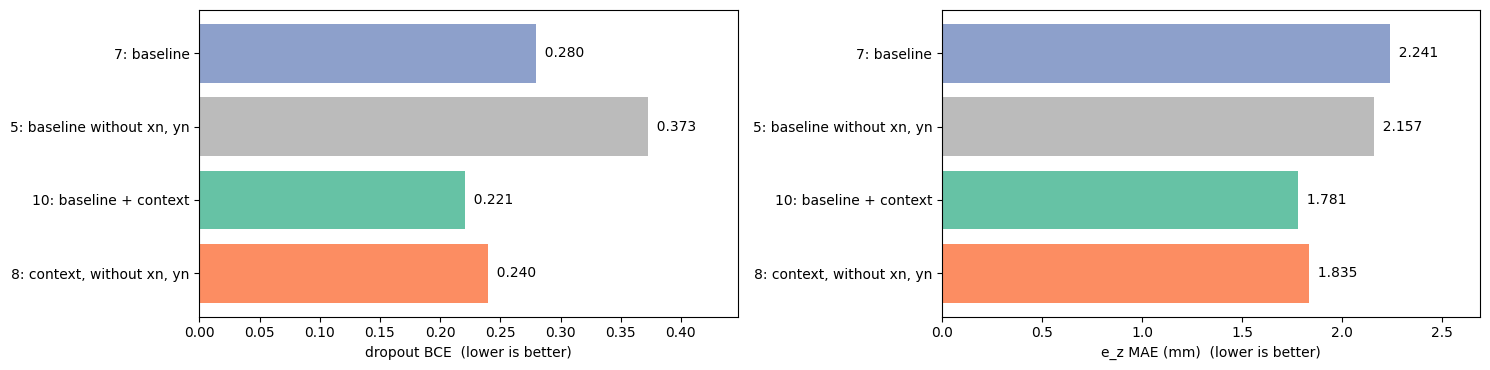

In [4]:
# ==========================================
# 3. COMPARE THE INPUT SETS
# ==========================================
order = list(INPUT_SETS)
g = res.groupby("inputs", sort=False)
fmt = (lambda col, n: f"{g[col].mean()[n]:.3f}") if len(SEEDS) == 1 else \
      (lambda col, n: f"{g[col].mean()[n]:.3f} ± {g[col].std()[n]:.3f}")
table = pd.DataFrame({col: [fmt(col, n) for n in order]
                      for col in ["dropout_bce", "ez_mae", "within_1sigma", "within_2sigma"]}, index=order)
table["best_epoch"] = [", ".join(str(v) for v in res[res.inputs == n].best_epoch) for n in order]
display(table)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
colors = ["#8da0cb", "#bbbbbb", "#66c2a5", "#fc8d62"]
for ax, col, label in zip(axes, ["dropout_bce", "ez_mae"], ["dropout BCE", "e_z MAE (mm)"]):
    m, lo, hi = g[col].mean()[order], g[col].min()[order], g[col].max()[order]
    ax.barh(range(len(order)), m, xerr=None if len(SEEDS) == 1 else [m - lo, hi - m], color=colors, capsize=4)
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order)
    ax.invert_yaxis()
    for i, val in enumerate(m):
        ax.text(hi.iloc[i], i, f"  {val:.3f}", va="center")
    ax.set_xlim(0, hi.max() * 1.2)
    ax.set_xlabel(label + "  (lower is better)")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part4b_input_sets.png"), dpi=110)
plt.show()

## 3. Baseline vs chosen set on one unseen view
Same view as in step 1 (TH1041AV view 100). Top: what the real sensor did. Middle: the 7-input baseline. Bottom: the chosen set (the 7 + the 3 context inputs). Look at the pocket: its real length on this workpiece is 30 mm (the upper part of the image).

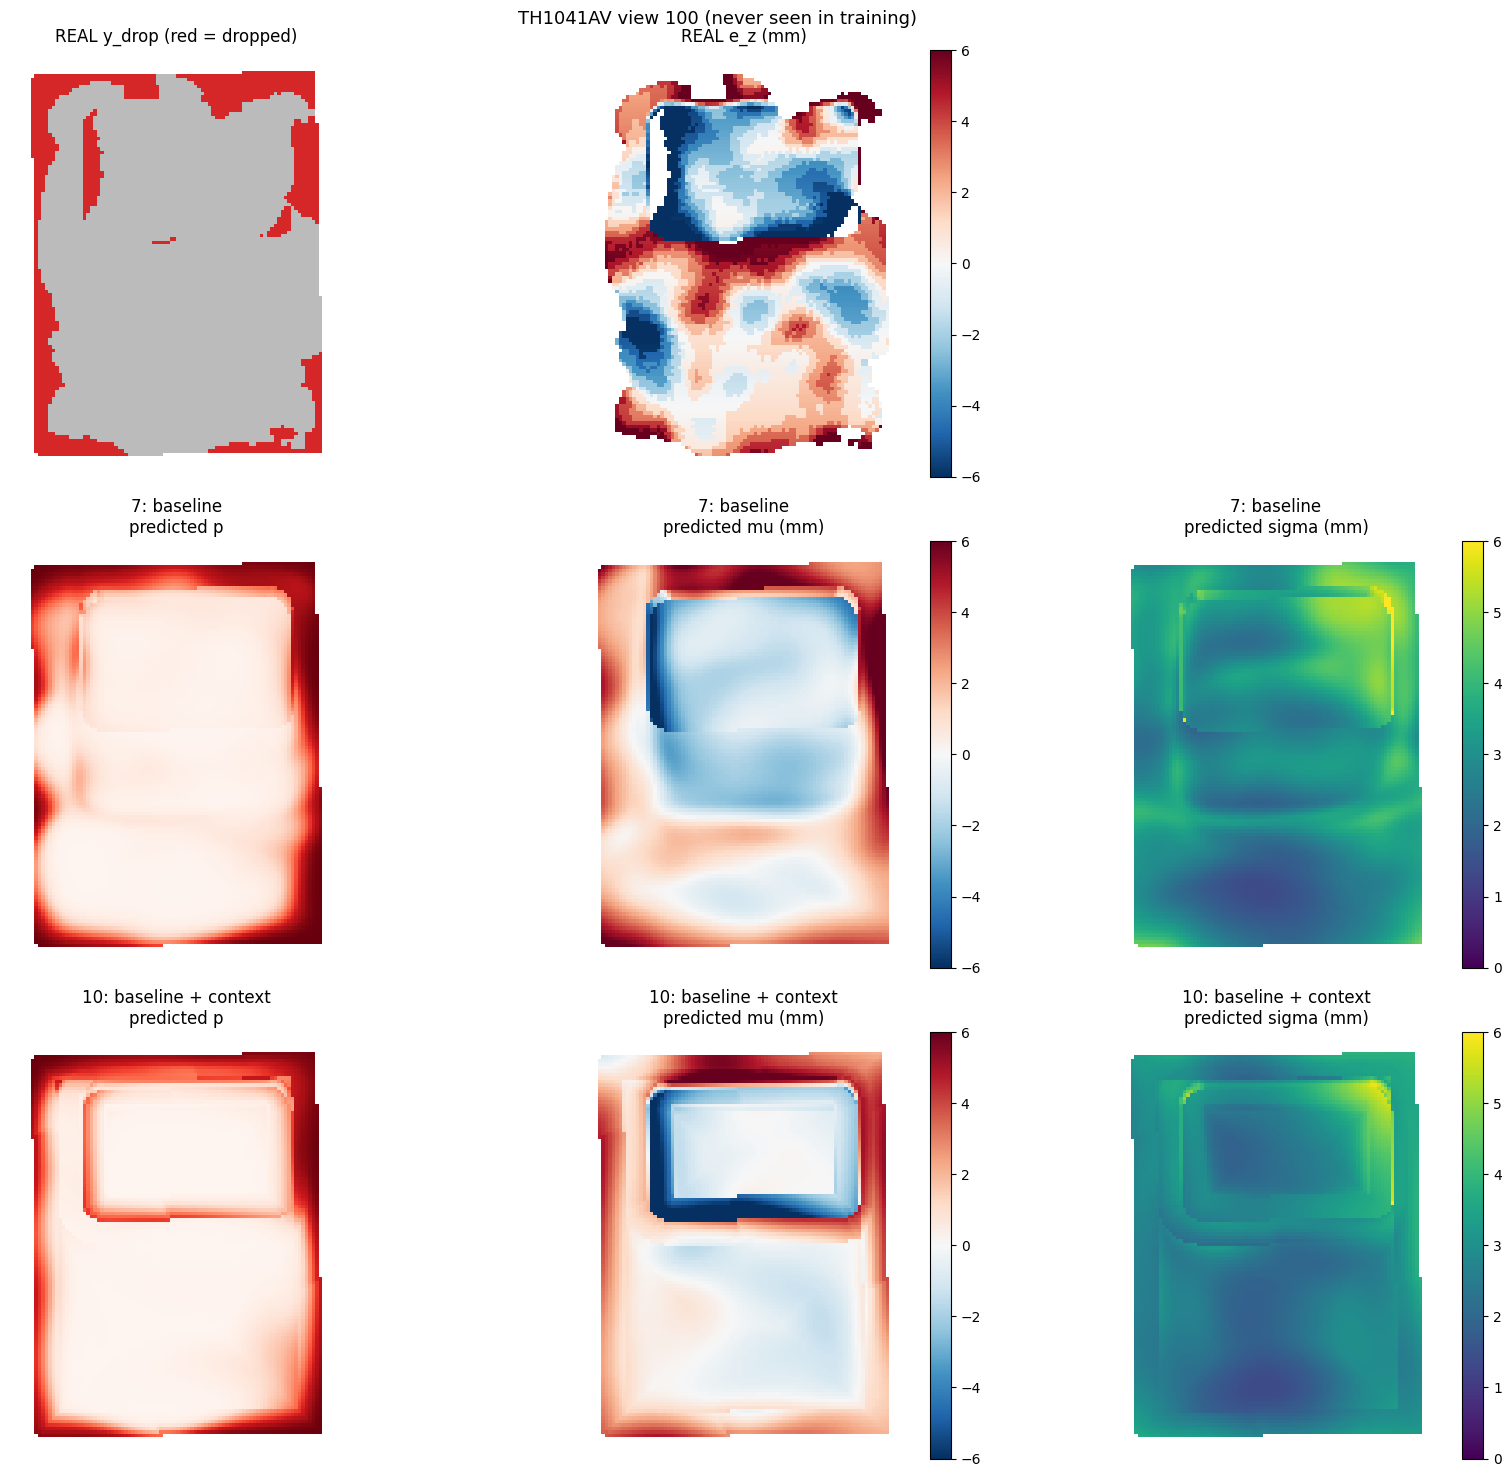

In [5]:
# ==========================================
# 4. MAPS: REAL vs BASELINE vs CHOSEN
# ==========================================
sel = (test.view == EXAMPLE_VIEW).to_numpy()
rows = test[sel]


def to_map(values):
    img = np.full((cam.height, cam.width), np.nan)
    img[rows.v.to_numpy(), rows.u.to_numpy()] = values
    return img


b0, b1, a0, a1 = rs.mask_bbox(~np.isnan(to_map(np.ones(sel.sum()))), margin=6)
crop = (slice(b0, b1), slice(a0, a1))
fig, axes = plt.subplots(3, 3, figsize=(16, 15))
panels = [(axes[0, 0], to_map(rows.y_drop), ListedColormap(["#bbbbbb", "#d62728"]), 0, 1, "REAL y_drop (red = dropped)"),
          (axes[0, 1], to_map(rows.e_z), "RdBu_r", -6, 6, "REAL e_z (mm)")]
for r_, name in [(1, BASELINE), (2, CHOSEN)]:
    p, mu, sd = preds[name]
    panels += [(axes[r_, 0], to_map(p[sel]), "Reds", 0, 1, f"{name}\npredicted p"),
               (axes[r_, 1], to_map(mu[sel]), "RdBu_r", -6, 6, f"{name}\npredicted mu (mm)"),
               (axes[r_, 2], to_map(sd[sel]), "viridis", 0, 6, f"{name}\npredicted sigma (mm)")]
for ax, img, cmap, lo, hi, title in panels:
    im = ax.imshow(img[crop], cmap=cmap, vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(title)
    if cmap != "Reds" and not isinstance(cmap, ListedColormap):
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
for ax in axes.flat:
    ax.axis("off")
fig.suptitle(f"{TEST_WP} view {EXAMPLE_VIEW} (never seen in training)", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part4b_example_view.png"), dpi=110)
plt.show()

## 4. Is the chosen model honest?
The same two checks as in step 1, for the chosen set (first seed): pixels where it says "30% chance of dropout" should drop about 30% of the time (dots on the diagonal), and the real errors measured in predicted σ should follow the bell curve (68% within ±1, 95% within ±2).

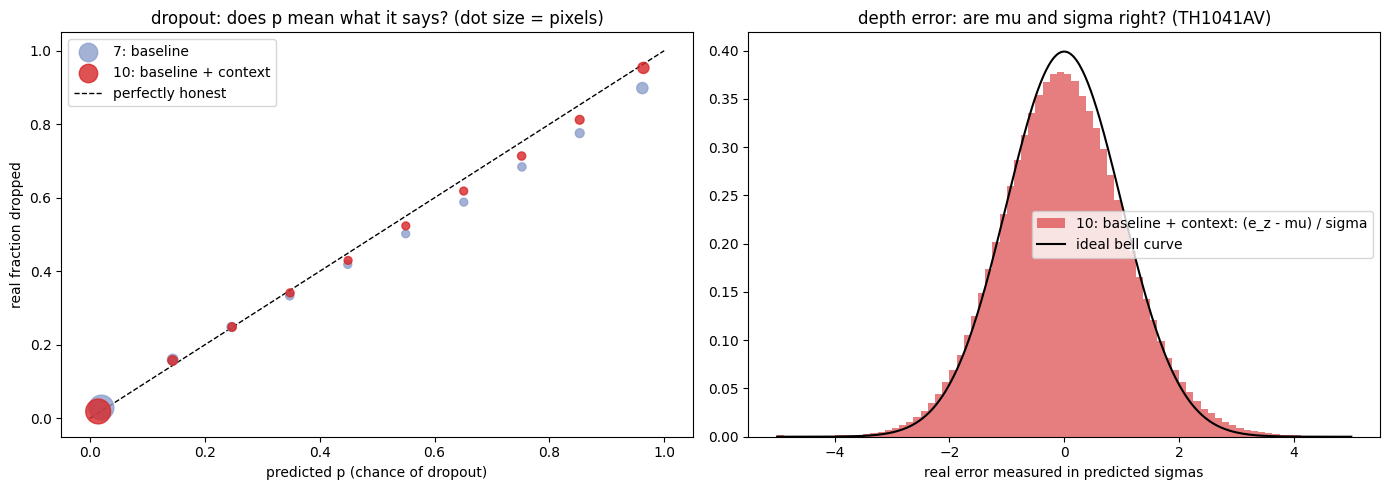

10: baseline + context: predicted dropout 22.8% vs real 22.5% | within 1 sigma 65.5% (ideal 68.3) | within 2 sigma 93.4% (ideal 95.4)


In [6]:
# ==========================================
# 5. CALIBRATION OF THE CHOSEN MODEL
# ==========================================
p, mu, sd = preds[CHOSEN]
kept = ~np.isnan(e_test)
z = (e_test[kept] - mu[kept]) / sd[kept]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, color in [(BASELINE, "#8da0cb"), (CHOSEN, "#d62728")]:
    pp = preds[name][0]
    b = np.clip(np.digitize(pp, np.linspace(0, 1, 11)) - 1, 0, 9)
    cal = pd.DataFrame(dict(b=b, pred=pp, real=y_test)).groupby("b").agg(n=("real", "size"), pred=("pred", "mean"), real=("real", "mean"))
    axes[0].scatter(cal.pred, cal.real, s=20 + 300 * cal.n / cal.n.max(), color=color, alpha=0.8, label=name, zorder=3)
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="perfectly honest")
axes[0].set_xlabel("predicted p (chance of dropout)")
axes[0].set_ylabel("real fraction dropped")
axes[0].set_title("dropout: does p mean what it says? (dot size = pixels)")
axes[0].legend()
xs = np.linspace(-5, 5, 400)
axes[1].hist(np.clip(z, -5, 5), bins=np.linspace(-5, 5, 81), density=True, color="#d62728", alpha=0.6, label=f"{CHOSEN}: (e_z - mu) / sigma")
axes[1].plot(xs, np.exp(-xs ** 2 / 2) / np.sqrt(2 * np.pi), "k", lw=1.5, label="ideal bell curve")
axes[1].set_xlabel("real error measured in predicted sigmas")
axes[1].set_title(f"depth error: are mu and sigma right? ({TEST_WP})")
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "part4b_calibration_chosen.png"), dpi=110)
plt.show()
s = rm.scores(y_test, e_test, p, mu, sd)
print(f"{CHOSEN}: predicted dropout {s['pred_drop'] * 100:.1f}% vs real {s['real_drop'] * 100:.1f}% | "
      f"within 1 sigma {s['within_1sigma'] * 100:.1f}% (ideal 68.3) | within 2 sigma {s['within_2sigma'] * 100:.1f}% (ideal 95.4)")

## Summary of Part 4 step 2 (test workpiece TH1041AV; split and training as in step 1; seed 42)
### Must understand
| Inputs | Dropout BCE | e_z MAE | Within ±1σ / ±2σ (ideal 68 / 95%) |
|---|---|---|---|
| 7: baseline | 0.280 | 2.24 mm | 63% / 91% |
| 5: baseline without `xn, yn` | 0.373 | 2.16 mm | 71% / 95% |
| **10: baseline + context (chosen)** | **0.221** | **1.78 mm** | 66% / 93% |
| 8: context, without `xn, yn` | 0.240 | 1.84 mm | 67% / 94% |

Seed 42 is fixed, so a rerun gives exactly these numbers. A check with seeds 42, 43 and 44 moved the scores by at most 0.013 BCE and gave the same ranking.

- **The context inputs are the big step.** The 7 inputs plus `edge_mm`, `deeper_mm` and `closer_mm` take dropout BCE from 0.280 to **0.221** and the depth error from 2.24 to **1.78 mm**.
- **The maps show why.** The chosen model draws the pocket at its **real size**: the baseline's oversized "average pocket" is gone. It also gets the sensor's pattern around steps right:
  - dropouts and "too far" (red) along the outer edges and the pocket rim;
  - "too close" (blue) on the pocket floor along its walls.
- **Why the 10 inputs (all 7 old + 3 new):**
  - nothing used before is removed, so the change is one clear addition, tested here as an ablation against the 7-input baseline;
  - `xn, yn` add a little on this test (0.240 → 0.221 BCE). Part of that may be the image-position shortcut, which is harmless for these four identical, centred blocks;
  - for differently shaped parts or off-centre views, the 8-input model (saved as well) would be the safer choice.
- **Calibration:**
  - predicted dropout is 22.8% against a real 22.5%, and the `p` dots lie on the diagonal;
  - `σ` is about 6% too narrow (65.5% within ±1σ). Part 5 measures the correction on validation views (never on the test workpiece).

### Know what it does
- All four sets were trained with the same split, patience training and seed. Every model is saved in `simulation/real2sim/test_11_real_pocket/`. **The chosen one is `model_10in_test-TH1041AV.pt`.**
- What still cannot be predicted is the smooth ±4–6 mm blobs on flat areas (12_3). They are why about 1.8 mm of error remains, and they are covered by `σ` plus the blurred noise of Part 5.

### Next (Part 5, simulator)
For any camera pose:
1. render the CAD;
2. compute the 10 inputs;
3. let the model give `p, μ, σ` per pixel;
4. draw drops and depth errors from **blurred** random fields (Cloud A / Cloud B), so dropouts come in patches and errors in blobs like the real ones;
5. unproject to 3D.